# 🧊 PyVista入門：CTボリュームと電極を3Dで描く

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Murakami-Shoya/study-notebooks/blob/main/notebooks/2026-10-20_pyvista-basics.ipynb)

**解説ページ**: [Notion教材ページ](https://app.notion.com/p/3ff3834a206d811d970ce1a88219e2e0)（データ構造・フィルタ・伝達関数の説明はこちら）

**日付**: 2026-10-20 ／ データはすべて合成（実データは使わない）

## 何を確かめるか

1. numpyの3次元配列は `pv.ImageData` の `point_data` に**Fortran順（x が最速）**で入る
2. 電極の座標（`PolyData` の点）に `glyph` で球を置くと、点ごとの値（`point_data`）が球に引き継がれ、色分けできる
3. `contour` は表面（`PolyData`）、`threshold` は体積の一部（`UnstructuredGrid`）を返し、金属のしきい値でCTから電極の位置を取り出せる
4. `add_volume` に3D SlicerのCT-Boneと同じ伝達関数を渡し、`shade=True` にすると陰影が付いて凹凸が見える
5. 伝達関数をHU方向にずらすと軟部組織が消え、骨と電極の重ね描きが見やすくなる

## どんなデータを用意するか

術後の頭部CTを真似た合成ボリューム。入れ子の楕円体で「空気・皮膚・頭蓋骨・脳」を作り、左側頭部に開頭窓（骨を外した領域）と 4×8 の硬膜下電極（金属）を置く。値はCT値（HU、Hounsfield unit）。正解は電極の座標 `elec_xyz`。

| 変数 | 形（shape） | 中身 |
|---|---|---|
| `vol` | `(nx, ny, nz)` = `(120, 140, 130)` | CT値 [HU]。空気 −1000、軟部組織 40、脳 30、骨 1000、金属 3071（CTの上限）。ボクセル 1.5 mm |
| `elec_xyz` | `(n_electrodes, 3)` = `(32, 3)` | 電極の中心座標 [mm]（正解） |
| `response` | `(n_electrodes,)` = `(32,)` | 電極ごとの合成の応答（1か所を中心にしたガウス型） |
| `grid` | `ImageData`、`n_points` = 2,184,000 | `vol` を載せた格子。`grid['HU']` は `(2184000,)` |

## シナリオ一覧

| # | 使うデータ | 何を動かすか | 確かめること | 期待する結果 | 解説の節 |
|---|---|---|---|---|---|
| S1 | `vol` | numpy → `ImageData`、直交断面 | 配列の並び順 | `reshape(dims, order='F')` で元の `vol` に戻る | 2. データ構造 |
| S2 | `elec_xyz`, `response` | `PolyData` → `glyph` で球 | 値の引き継ぎ | 球の点数 = 電極数 × 球1個の点数、`response` が残る | 2・4 |
| S3 | `grid` | `contour`（骨）と `threshold`（金属） | 返る型と電極の検出 | 金属の塊が32個、中心の誤差 < 1ボクセル | 4. フィルタ |
| S4 | `grid` | CT-Boneの伝達関数で `shade` なし／あり | 陰影の効果 | 陰影ありの方が明暗の変動係数（標準偏差÷平均）が大きい | 5・6 |
| S5 | `grid`, `elec_xyz` | 伝達関数を +200 HU ずらし、電極の球を重ねる | 重ね描きの図 | 骨と色付き電極が見える図をpngで保存 | 6. CT＋電極 |

## 準備：環境・定数・補助関数

In [1]:
# 環境の準備：pyvistaを入れ、画面のないLinux（Colabなど）では仮想ディスプレイXvfbを起動する
import os, sys, time, shutil, subprocess, importlib.util
IN_COLAB = 'google.colab' in sys.modules
if importlib.util.find_spec('pyvista') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pyvista'], check=True)
if IN_COLAB and shutil.which('Xvfb') is None:
    subprocess.run('apt-get -qq update && apt-get -qq install -y xvfb', shell=True, check=True)
if sys.platform.startswith('linux') and not os.environ.get('DISPLAY') and shutil.which('Xvfb'):
    subprocess.Popen(['Xvfb', ':99', '-screen', '0', '1280x1024x24'],
                     stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    os.environ['DISPLAY'] = ':99'
    time.sleep(2)  # Xvfbの起動待ち
print('Colab:', IN_COLAB, '| DISPLAY:', os.environ.get('DISPLAY'))

Colab: False | DISPLAY: :99


In [2]:
# ライブラリと定数（形・CT値・乱数）
import numpy as np, pyvista as pv, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.ndimage import gaussian_filter
pv.OFF_SCREEN = True                      # 画面に出さず画像として受け取る
SEED, DIMS, SPACING = 0, (120, 140, 130), 1.5          # ボクセル数 (nx, ny, nz)、1ボクセル [mm]
HU = dict(air=-1000, soft=40, brain=30, bone=1000, metal=3071)
SKIN, SKULL_OUT, SKULL_IN = (78, 98, 88), (72, 92, 82), (66, 86, 76)  # 楕円体の半径 [mm]
N_ROWS, N_COLS, PITCH, ELEC_R = 4, 8, 10.0, 3.0           # 電極グリッドと電極半径 [mm]
WIN = (640, 520)                                       # 描画する画像の大きさ [px]
print('pyvista', pv.__version__, '| n_voxels:', np.prod(DIMS))

pyvista 0.49.1 | n_voxels: 2184000


In [3]:
# 電極の座標：左側頭の脳表に 4×8 グリッド → (n_electrodes, 3) [mm]
def make_electrodes():
    ys = (np.arange(N_COLS) - (N_COLS - 1) / 2) * PITCH            # 前後方向 (8,)
    zs = (np.arange(N_ROWS) - (N_ROWS - 1) / 2) * PITCH + 10       # 上下方向 (4,)
    Y, Z = [a.ravel() for a in np.meshgrid(ys, zs, indexing='ij')]  # (32,), (32,)
    a, b, c = np.array(SKULL_IN) - ELEC_R                          # 骨の内側に接する楕円体
    X = -a * np.sqrt(1 - (Y / b) ** 2 - (Z / c) ** 2)              # 左側（x < 0）の表面
    return np.stack([X, Y, Z], axis=1)                             # (32, 3)

# 合成の応答：1電極を中心にしたガウス型＋ノイズ → (n_electrodes,)
def make_response(elec_xyz, rng, center=13, width=15.0):
    d = np.linalg.norm(elec_xyz - elec_xyz[center], axis=1)        # (32,)
    return np.exp(-(d / width) ** 2) + 0.05 * rng.standard_normal(len(d))

In [4]:
# 合成頭部CT：入れ子の楕円体＋開頭窓＋金属電極 → (nx, ny, nz) [HU]
def make_head_ct(elec_xyz, rng):
    axes = [(np.arange(n) - (n - 1) / 2) * SPACING for n in DIMS]  # 各軸の座標 [mm]
    X, Y, Z = np.meshgrid(*axes, indexing='ij')                    # 各 (nx, ny, nz)
    r = lambda s: np.sqrt((X / s[0]) ** 2 + (Y / s[1]) ** 2 + (Z / s[2]) ** 2)
    vol = np.full(DIMS, HU['air'], np.float32)
    vol[r(SKIN) <= 1], vol[r(SKULL_OUT) <= 1], vol[r(SKULL_IN) <= 1] = HU['soft'], HU['bone'], HU['brain']
    window = (X < 0) & (np.abs(Y) < 50) & (np.abs(Z - 10) < 28) & (r(SKULL_IN) > 1) & (r(SKULL_OUT) <= 1)
    vol[window] = HU['soft']                                       # 開頭窓：電極の上の骨を外す
    for p in elec_xyz:                                             # 金属の電極（半径 ELEC_R の球）
        vol[(X - p[0]) ** 2 + (Y - p[1]) ** 2 + (Z - p[2]) ** 2 <= ELEC_R ** 2] = HU['metal']
    vol = gaussian_filter(vol, sigma=1.2)                          # 部分容積効果のぼけ
    return vol + 10 * rng.standard_normal(DIMS).astype(np.float32), axes

In [5]:
# 3D SlicerのCT-Bone伝達関数（presets.xml の値）→ 不透明度 (n,) と色マップ
CT_BONE_HU  = np.array([-3024, -16.4458, 641.385, 3071])
CT_BONE_OPA = np.array([0, 0, 0.715686, 0.705882])
CT_BONE_RGB = np.array([[0, 0, 0], [0.729, 0.255, 0.302], [0.906, 0.816, 0.553], [1, 1, 1]])
def ct_bone_tf(clim, shift=0.0, n=128):                           # n≠256：同じ長さだと0〜255扱い（0.49.1）
    hu = np.linspace(*clim, n)                                     # 色表の各段のHU (n,)
    opa = np.interp(hu, CT_BONE_HU + shift, CT_BONE_OPA)           # (n,)
    rgb = np.stack([np.interp(hu, CT_BONE_HU + shift, CT_BONE_RGB[:, k]) for k in range(3)], 1)
    return opa, ListedColormap(rgb)                                # (n,), n色
# 画像を並べて表示（図の文字は英語）: list of (H, W, 3)
def show(images, titles):
    fig, axs = plt.subplots(1, len(images), figsize=(5 * len(images), 4.2), squeeze=False)
    for ax, img, t in zip(axs[0], images, titles): ax.imshow(img); ax.set_title(t); ax.axis('off')
    plt.tight_layout(); plt.show()

## S1. numpy配列を `ImageData` に載せる
合成CT `vol` を作って格子に載せ、`point_data` の並び順（Fortran順）を確かめる。正中と電極13を通る3方向の断面を灰色で描く。

vol: (120, 140, 130) | elec_xyz: (32, 3) | response: (32,)
grid.n_points: 2184000 | grid[HU]: (2184000,) | n_cells: 2133789


/tmp/ipykernel_443149/491002897.py:12: PyVistaDeprecationWarning: 
/tmp/ipykernel_443149/491002897.py:12: Arguments 'x', 'y', 'z' must be passed as keyword arguments to function 'DataObjectFilters.slice_orthogonal'.
From version 0.50, passing these as positional arguments will result in a TypeError.
  p = pv.Plotter(window_size=WIN); p.add_mesh(grid.slice_orthogonal(0, *elec_xyz[13, 1:]), cmap='gray', clim=(-200, 1500))


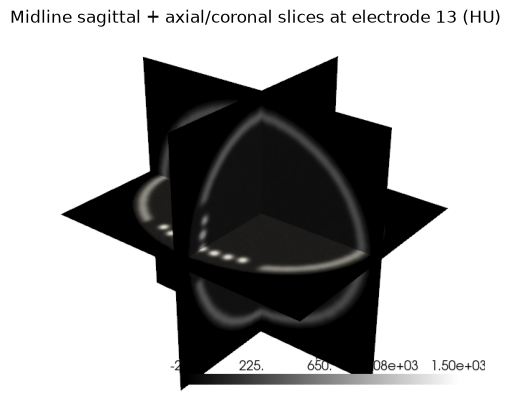

In [6]:
# 合成データを作り、ImageDataに載せて並び順を確かめる
rng = np.random.default_rng(SEED)
elec_xyz = make_electrodes();  response = make_response(elec_xyz, rng)
vol, axes = make_head_ct(elec_xyz, rng)
print('vol:', vol.shape, '| elec_xyz:', elec_xyz.shape, '| response:', response.shape)
grid = pv.ImageData(dimensions=DIMS, spacing=(SPACING,) * 3, origin=[a[0] for a in axes])
grid['HU'] = vol.ravel(order='F')                    # (nx*ny*nz,)：x が最も速く変わる
print('grid.n_points:', grid.n_points, '| grid[HU]:', grid['HU'].shape, '| n_cells:', grid.n_cells)
assert np.array_equal(grid['HU'].reshape(DIMS, order='F'), vol)
i, j, k = 10, 20, 30                                 # 任意のボクセルで座標も一致するか
assert np.allclose(grid.points[i + j * DIMS[0] + k * DIMS[0] * DIMS[1]], [axes[0][i], axes[1][j], axes[2][k]])
p = pv.Plotter(window_size=WIN); p.add_mesh(grid.slice_orthogonal(0, *elec_xyz[13, 1:]), cmap='gray', clim=(-200, 1500))
p.view_vector((-1, -0.8, 0.7), viewup=(0, 0, 1)); p.camera.zoom(1.3); img_s1 = p.screenshot(return_img=True); p.close()
show([img_s1], ['Midline sagittal + axial/coronal slices at electrode 13 (HU)'])

**観察**：`ravel(order='F')` で入れた値は `reshape(DIMS, order='F')` で元に戻り、点の座標も一致した。C順（numpyの既定）で入れると軸が入れ替わるので注意。

## S2. 電極を `PolyData` にして球のグリフを置く
電極座標32点に `response` を持たせ、`glyph` で球（金属の1.4倍の半径）に置き換える。球の点数と、値が引き継がれているかを見る。

elec.points: (32, 3) | elec[response]: (32,)
sphere.n_points: 226 | balls.n_points: 7232
balls[response]: (7232,)


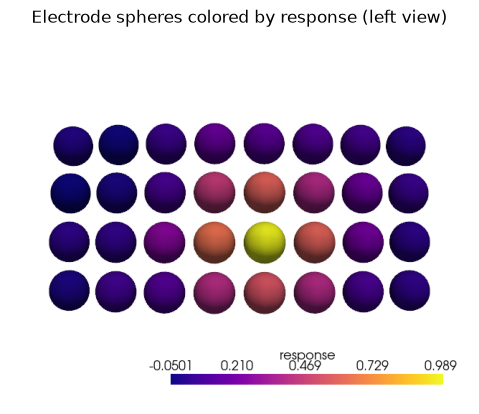

In [7]:
# 電極の点群に値を持たせ、球のグリフに置き換える
elec = pv.PolyData(elec_xyz);  elec['response'] = response
print('elec.points:', elec.points.shape, '| elec[response]:', elec['response'].shape)
sphere = pv.Sphere(radius=1.4 * ELEC_R, theta_resolution=16, phi_resolution=16)  # 金属より少し大きく
balls = elec.glyph(geom=sphere, scale=False, orient=False)        # 1点 → 球1個
print('sphere.n_points:', sphere.n_points, '| balls.n_points:', balls.n_points)
print('balls[response]:', balls['response'].shape)
assert balls.n_points == elec.n_points * sphere.n_points
assert np.isclose(balls['response'].max(), response.max())         # 値が球の全点へ複製される
p = pv.Plotter(window_size=WIN)
p.add_mesh(balls, scalars='response', cmap='plasma', smooth_shading=True)
p.view_yz(negative=True); p.camera.zoom(1.2); img_s2 = p.screenshot(return_img=True); p.close()
show([img_s2], ['Electrode spheres colored by response (left view)'])

**観察**：球の点数は 32 × 球1個の点数になり、`response` は各球の全点にコピーされた。だから `scalars='response'` だけで電極ごとに色が付く。

## S3. `contour` と `threshold`：骨の表面と金属の電極を取り出す
骨は 500 HU の等値面（`contour`）、金属は 1300 HU 以上（`threshold`）で取り出す。金属を連結成分に分け、塊の数と中心の誤差を正解 `elec_xyz` と比べる。

PolyData 101870 | UnstructuredGrid 1132
n_regions: 32
centroids: (32, 3) | max error [mm]: 0.4


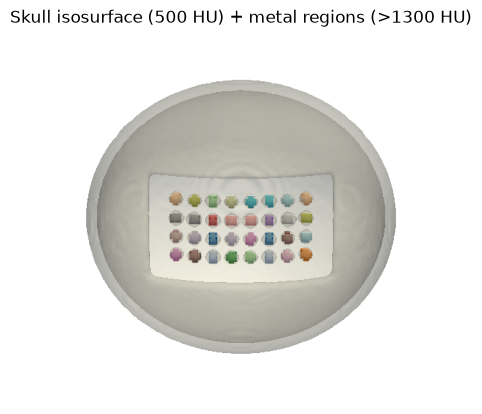

In [8]:
# 骨の等値面と金属のしきい値抽出を比べ、電極の位置を検出する
skull = grid.contour([500], scalars='HU')                         # 表面 → PolyData
metal = grid.threshold(1300, scalars='HU')                        # 体積の一部 → UnstructuredGrid
print(type(skull).__name__, skull.n_points, '|', type(metal).__name__, metal.n_cells)
bodies = metal.connectivity(extraction_mode='all')                # 塊ごとに RegionId
ids = np.unique(bodies['RegionId']);  print('n_regions:', len(ids))
cc, rid = bodies.cell_centers().points, bodies.cell_data['RegionId']   # (n_cells, 3), (n_cells,)
cent = np.array([cc[rid == r].mean(0) for r in ids])                # (n_regions, 3)
err = np.linalg.norm(cent[:, None] - elec_xyz[None], axis=2).min(1)             # (n_regions,)
print('centroids:', cent.shape, '| max error [mm]:', err.max().round(2))
assert len(ids) == len(elec_xyz) and err.max() < SPACING
p = pv.Plotter(window_size=WIN); p.add_mesh(skull, color='ivory', opacity=0.35, smooth_shading=True)
p.add_mesh(bodies, scalars='RegionId', cmap='tab20', show_scalar_bar=False)
p.view_yz(negative=True); p.camera.elevation = 15; p.camera.zoom(1.3); img_s3 = p.screenshot(return_img=True); p.close()
show([img_s3], ['Skull isosurface (500 HU) + metal regions (>1300 HU)'])

**観察**：`contour` は `PolyData`、`threshold` は `UnstructuredGrid` を返した。金属の塊は32個で、中心は正解から1ボクセル未満にあった。

## S4. ボリュームレンダリング：CT-Boneの伝達関数と `shade`
3D SlicerのCT-Boneと同じ不透明度・色の伝達関数で `add_volume` する。陰影なし／あり（ambient 0.1・diffuse 0.9・specular 0.2・線形補間、Slicerと同じ値）を並べ、明暗の変動係数（標準偏差÷平均）を比べる。

opacity TF: (128,)


image: (520, 640, 3) | CV flat/shaded: [0.16 0.29]


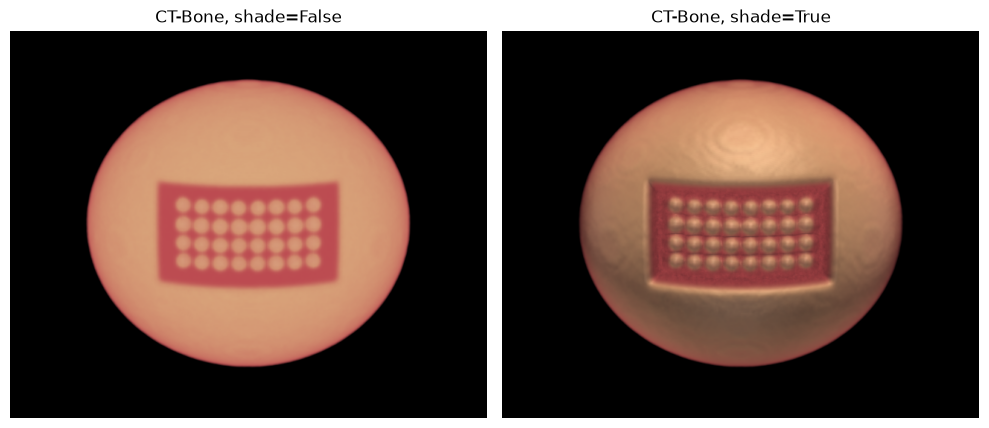

In [9]:
# CT-Boneの伝達関数で陰影なし／ありを描き比べる
CLIM = (-1000, 3000);  print('opacity TF:', ct_bone_tf(CLIM)[0].shape)
def render_volume(shade, shift=0.0, balls=None):                  # → (H, W, 3)
    p = pv.Plotter(window_size=WIN); p.set_background('black'); opa, cmap = ct_bone_tf(CLIM, shift)
    act = p.add_volume(grid, scalars='HU', clim=CLIM, opacity=opa, cmap=cmap, shade=shade,
                       opacity_unit_distance=SPACING, show_scalar_bar=False)
    act.prop.interpolation_type = 'linear'                         # Slicerと同じ線形補間（既定は nearest）
    act.prop.ambient, act.prop.diffuse, act.prop.specular, act.prop.specular_power = 0.1, 0.9, 0.2, 10
    if balls is not None: p.add_mesh(balls, scalars='response', cmap='plasma', smooth_shading=True, specular=0.5, scalar_bar_args={'title': 'response (a.u.)', 'color': 'white'})
    p.view_yz(negative=True); p.camera.elevation = 15; p.camera.zoom(1.5)
    img = p.screenshot(return_img=True); p.close(); return img
flat, shaded = render_volume(False), render_volume(True)
cv = [g[g > 0].std() / g[g > 0].mean() for g in (flat.mean(2), shaded.mean(2))]  # 明暗の変動係数
print('image:', flat.shape, '| CV flat/shaded:', np.round(cv, 3));  assert cv[1] > cv[0]
show([flat, shaded], ['CT-Bone, shade=False', 'CT-Bone, shade=True'])

**観察**：陰影ありの方が明暗の変動係数が大きく、頭蓋の丸みや開頭窓の縁が立体的に見えた。陰影なしは色と不透明度だけなので平板になる。

## S5. CTのボリューム＋電極の球を重ねる
CT-Boneのままだと皮膚（約 40 HU）が薄く写る。伝達関数を +200 HU ずらして軟部組織を消し、S2の電極の球を `response` で色付けして重ね、pngで保存する。

opacity at 40 HU (shift 0 / +200): [0.061 0.   ]


overlay: (520, 640, 3) | saved: True


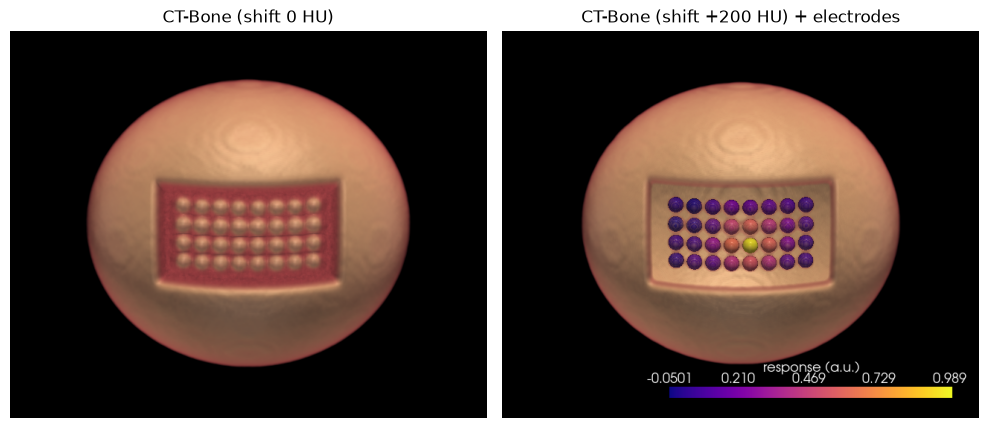

In [10]:
# 伝達関数をずらし、電極の球を重ねた図を保存する
skin_opa = [np.interp(HU['soft'], CT_BONE_HU + s, CT_BONE_OPA) for s in (0, 200)]
print('opacity at 40 HU (shift 0 / +200):', np.round(skin_opa, 3))
overlay = render_volume(True, shift=200, balls=balls)
plt.imsave('pyvista_ct_electrodes.png', overlay)
print('overlay:', overlay.shape, '| saved:', os.path.exists('pyvista_ct_electrodes.png'))
assert skin_opa[1] == 0 and overlay.shape == (WIN[1], WIN[0], 3)
show([shaded, overlay], ['CT-Bone (shift 0 HU)', 'CT-Bone (shift +200 HU) + electrodes'])

**観察**：+200 HU ずらすと 40 HU の不透明度が 0 になり、皮膚が消えて開頭窓の中の電極が見えた。球の色は `response` の山（電極13の周り）を示す。

## まとめ
- `ImageData` はFortran順、電極は `PolyData`＋`glyph`、取り出しは `contour`（表面）と `threshold`（体積）。
- CT-Boneの伝達関数＋`shade=True`（ambient 0.1・diffuse 0.9・specular 0.2）でSlicerに近い陰影になり、HUをずらすと軟部組織を隠せる。